Now that we have a list of sources that have relevant observations, we can start looking towards downloading their visibilities and making a dynamic spectra. Lets start with just one star and one visibility file.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.table import Column
import tqdm
from astropy.table import join
from astroquery.simbad import Simbad
from ipyaladin import Aladin
from astroquery.casda import Casda
from astropy.coordinates import SkyCoord
from astroquery.utils.tap.core import TapPlus
import astropy.units as u
import anywidget
import ipywidgets
import ipyaladin
import dstools
import os

ModuleNotFoundError: No module named 'numpy'

In [2]:
OPAL_USER = 'jfer9940@uni.sydney.edu.au'
Casda.login(username=OPAL_USER, store_password=True)

INFO: Authenticating jfer9940@uni.sydney.edu.au on CASDA ... [astroquery.casda.core]
INFO: Authentication successful! [astroquery.casda.core]


In [3]:
obs_data = Table.read('data/source_obs_data.csv')

The star I want to start with is V* AI Lep (just cause it has a cool name). Lets get a list of observations for this source.

In [20]:
source_data = obs_data[obs_data['Simbad_ID'] == 'V* AI Lep']
ra = source_data[0]['Archival_ra']
dec = source_data[0]['Archival_dec']
coords = SkyCoord(ra = ra*u.deg, dec = dec*u.deg, frame='icrs')

In [52]:
coords

<SkyCoord (ICRS): (ra, dec) in deg
    (85.08647402, -19.66975597)>

In [24]:
result_table = Casda.query_region(coords, radius="5 arcmin")
public_data = Casda.filter_out_unreleased(result_table)

min_exptime = 60*60 # 1 Hour minimum time
dataproduct_type = 'visibility' # We want visibility data

mask = (public_data['dataproduct_type'] == dataproduct_type) & (public_data['t_exptime'] >= min_exptime)
results = public_data[mask]

Note there are a lot of duplicates here. First, we want to get rid of the pre-processed data (i.e. the HIPASS files), so lets only keep files that contain 'beam' in their filename.

In [26]:
fnames = results['filename']
mask = ['beam' in f for f in fnames]
raw_data = results[mask]

Lastly, we only want one beam per observation. Noting that the table is sorted by distance, we can simply return the first instance of a given obs_id as our final step of filtering to get our list of observations.

In [30]:
# Get the index of unique obs_ids
_, unique_indices = np.unique(results['obs_id'], return_index=True)
unique_observations = raw_data[unique_indices]

In [31]:
unique_observations

distance,dataproduct_type,calib_level,obs_collection,obs_id,obs_publisher_did,access_url,access_format,access_estsize,target_name,s_ra,s_dec,s_fov,s_region,s_resolution,s_xel1,s_xel2,t_min,t_max,t_exptime,t_resolution,t_xel,em_min,em_max,em_res_power,em_xel,o_ucd,pol_states,pol_xel,facility_name,instrument_name,dataproduct_subtype,em_ucd,em_unit,em_resolution,s_resolution_min,s_resolution_max,s_ucd,s_unit,obs_release_date,quality_level,thumbnail_id,filename
deg,,,,,,,,kbyte,,deg,deg,deg,,arcsec,,,d,d,s,s,,m,m,,,,,,,,,,,m,arcsec,arcsec,,,,,,
float64,str255,int32,str255,str255,str255,str2000,str255,int64,str255,float64,float64,float64,str200,float64,int64,int64,float64,float64,float64,float64,int64,float64,float64,float64,int64,str255,str255,int64,str255,str255,str255,str255,str255,float64,float64,float64,str255,str255,str24,str15,int64,str1000
0.9325720344369403,visibility,1,FLASH,ASKAP-63484,scan-502433-3373660,https://data.csiro.au/casda_vo_proxy/vo/datalink/links?ID=scan-502433-3373660,application/x-votable+xml;content=datalink,6716020,FLASH_368,85.6511743152092,-20.43677429874182,1.82165,POLYGON ICRS 86.5619993152092 -20.43677429874182 86.56020201012988 -20.379583123791534 86.55481718803397 -20.322617656280613 86.54586610035416 -20.266102712884276 86.53338407294419 -20.210261332264892,--,--,--,60497.23851851852,60497.32204861111,7216.999999783002,--,1,0.29964540971199255,0.4207668124630408,--,288,phys.polarisation,/XX/XY/YX/YY/,4,ASKAP,,,em.wl,m,0.0004205604262189176,--,--,pos.eq,deg,2024-08-05T02:30:41.003Z,GOOD,--,scienceData.FLASH_368.SB63484.FLASH_368.beam11_averaged_cal.leakage.ms.tar
0.31950489313910607,visibility,1,WALLABY,ASKAP-79867,scan-763915-3770083,https://data.csiro.au/casda_vo_proxy/vo/datalink/links?ID=scan-763915-3770083,application/x-votable+xml;content=datalink,13504220,WALLABY_0542-21B,84.75764663370268,-19.74882387412824,1.14011,POLYGON ICRS 85.32770163370267 -19.74882387412824 85.32657676037685 -19.71302982451796 85.32320657976051 -19.67737703766874 85.31760439241683 -19.642006218842077 85.30979230761986 -19.60705696050048 8,--,--,--,61013.53399305556,61013.8675,28814.99999994412,--,1,0.20811828182379133,0.2312337824863803,--,144,phys.polarisation,/XX/XY/YX/YY/,4,ASKAP,,,em.wl,m,0.00016052431015686782,--,--,pos.eq,deg,2026-03-05T00:26:12.047Z,GOOD,--,scienceData.WALLABY_0542-21B.SB79867.WALLABY_0542-21B.beam17_averaged_cal.leakage.ms.tar
0.5496235480974605,visibility,1,WALLABY,ASKAP-79907,scan-763815-3769983,https://data.csiro.au/casda_vo_proxy/vo/datalink/links?ID=scan-763815-3769983,application/x-votable+xml;content=datalink,13504140,WALLABY_0542-21A,85.23480588548763,-20.201403236502077,1.14011,POLYGON ICRS 85.80486088548763 -20.201403236502077 85.8037360121618 -20.165609186891796 85.80036583154546 -20.129956400042577 85.79476364420178 -20.094585581215913 85.78695155940481 -20.05963632287431,--,--,--,61014.522361111114,61014.85585648148,28813.99999971036,--,1,0.20811828182379133,0.2312337824863803,--,144,phys.polarisation,/XX/XY/YX/YY/,4,ASKAP,,,em.wl,m,0.00016052431015686782,--,--,pos.eq,deg,2026-03-05T00:25:04.041Z,GOOD,--,scienceData.WALLABY_0542-21A.SB79907.WALLABY_0542-21A.beam05_averaged_cal.leakage.ms.tar


So our shortest observation (which I will use as a test case) is the 2 hour FLASH observation. Lets download this file and then see if we can make a dynamic spectra.

In [46]:
to_download = unique_observations[0:1]

In [43]:
# Set download path
save_dir = '../visibility_files'
os.makedirs(save_dir, exist_ok=True)

In [47]:
url_list = Casda.stage_data(to_download)
file_list = Casda.download_files(url_list, savedir=save_dir)

Now let's try and plot this

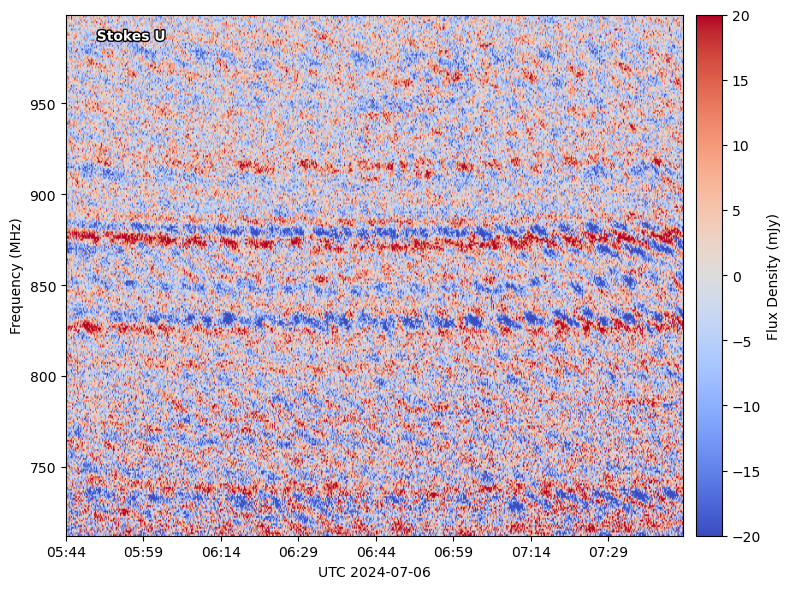

In [15]:
import matplotlib.pyplot as plt
from dstools.dynamic_spectrum import DynamicSpectrum
from dstools.plotting import plot_ds

# Create DS object
ds = DynamicSpectrum(ds_path='../visibility_files/corrected_data_ds_test')

# Plot Stokes I dynamic spectrum with real visibilities and color-scale clipped at 20 mJy
fig, ax = plot_ds(ds, stokes='U')


plt.show()

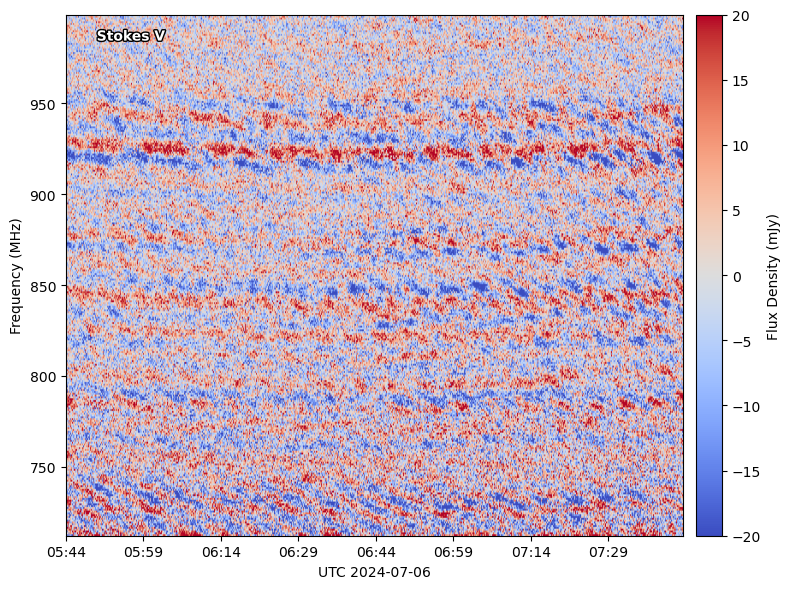

In [11]:
## Create DS object
ds1 = DynamicSpectrum(ds_path='../visibility_files/2nd_ds_test')

# Plot Stokes I dynamic spectrum with real visibilities and color-scale clipped at 20 mJy
fig, ax = plot_ds(ds, stokes='V')


plt.show()

# Testing with a 2nd star

Given the image for AI Lep was very bad (and it looked like a non-detection in FLASH), I want to try with a different star to see if I am getting the same issues or if the source itself is the problem. The second coolest star name is V* TY Col, so let's try that one instead.

In [8]:
source_data = obs_data[obs_data['Simbad_ID'] == 'V* TY Col']
ra = source_data[0]['Archival_ra']
dec = source_data[0]['Archival_dec']
coords = SkyCoord(ra = ra*u.deg, dec = dec*u.deg, frame='icrs')
coords

<SkyCoord (ICRS): (ra, dec) in deg
    (89.46168457, -38.06762489)>

In [9]:
result_table = Casda.query_region(coords, radius="5 arcmin")
public_data = Casda.filter_out_unreleased(result_table)

min_exptime = 60*60 # 1 Hour minimum time
dataproduct_type = 'visibility' # We want visibility data

mask = (public_data['dataproduct_type'] == dataproduct_type) & (public_data['t_exptime'] >= min_exptime)
results = public_data[mask]

fnames = results['filename']
mask = ['beam' in f for f in fnames]
raw_data = results[mask]

# Get the index of unique obs_ids
_, unique_indices = np.unique(results['obs_id'], return_index=True)
unique_observations = raw_data[unique_indices]
unique_observations

distance,dataproduct_type,calib_level,obs_collection,obs_id,obs_publisher_did,access_url,access_format,access_estsize,target_name,s_ra,s_dec,s_fov,s_region,s_resolution,s_xel1,s_xel2,t_min,t_max,t_exptime,t_resolution,t_xel,em_min,em_max,em_res_power,em_xel,o_ucd,pol_states,pol_xel,facility_name,instrument_name,dataproduct_subtype,em_ucd,em_unit,em_resolution,s_resolution_min,s_resolution_max,s_ucd,s_unit,obs_release_date,quality_level,thumbnail_id,filename
deg,,,,,,,,kbyte,,deg,deg,deg,,arcsec,,,d,d,s,s,,m,m,,,,,,,,,,,m,arcsec,arcsec,,,,,,
float64,str255,int32,str255,str255,str255,str2000,str255,int64,str255,float64,float64,float64,str200,float64,int64,int64,float64,float64,float64,float64,int64,float64,float64,float64,int64,str255,str255,int64,str255,str255,str255,str255,str255,float64,float64,float64,str255,str255,str24,str15,int64,str1000
0.36252521892574885,visibility,1,FLASH,ASKAP-60195,scan-446676-3317903,https://data.csiro.au/casda_vo_proxy/vo/datalink/links?ID=scan-446676-3317903,application/x-votable+xml;content=datalink,6750610,FLASH_216,89.91191766292005,-38.14455061927553,1.82165,POLYGON ICRS 90.82274266292005 -38.14455061927553 90.82094535784073 -38.08735944432524 90.81556053574481 -38.03039397681432 90.806609448065 -37.97387903341799 90.79412742065503 -37.918037652798596 90.,--,--,--,60388.55378472222,60388.63730324074,7216.000000177883,--,1,0.29964540971199255,0.4207668124630408,--,288,phys.polarisation,/XX/XY/YX/YY/,4,ASKAP,,,em.wl,m,0.0004205604262189176,--,--,pos.eq,deg,2024-06-10T06:52:15.055Z,UNCERTAIN,--,scienceData.FLASH_216.SB60195.FLASH_216.beam14_averaged_cal.leakage.ms.tar


At least we don't have to choose which one to look at this time?

In [10]:
to_download = unique_observations[0:1]

# Set download path
save_dir = '../visibility_files'
os.makedirs(save_dir, exist_ok=True)

In [11]:
url_list = Casda.stage_data(to_download)
file_list = Casda.download_files(url_list, savedir=save_dir)